<a href="https://colab.research.google.com/github/Pratham8765/Customer-Churn-Prediction/blob/main/Telco_Customer_Churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Customers: 7,043 | churn rate: 26.5% | majority baseline accuracy: 73.5%

5-fold CV results (training data):
                     accuracy  precision  recall     f1  roc_auc
Majority baseline       0.735      0.000   0.000  0.000    0.500
Logistic Regression     0.749      0.517   0.801  0.629    0.846
Decision Tree           0.742      0.510   0.777  0.615    0.827
Random Forest           0.775      0.559   0.724  0.631    0.845

Best model by CV F1: Random Forest
              precision    recall  f1-score   support

    No churn       0.89      0.78      0.83      1035
       Churn       0.55      0.74      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409

ROC-AUC: 0.842
Confusion matrix -> caught churners: 276 of 374 | false alarms: 225 | missed: 98


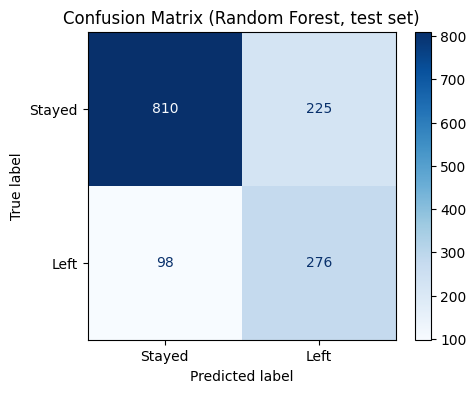

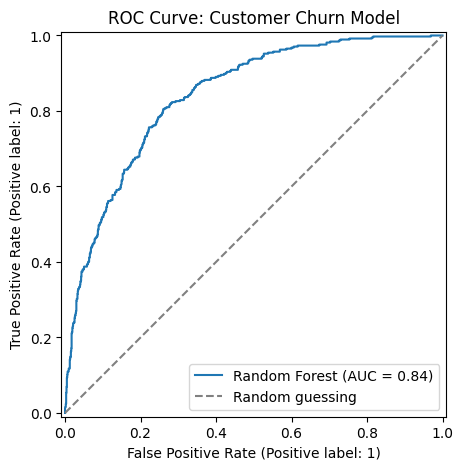


Threshold trade-off (test set):
 threshold  flagged  precision  recall   f1
       0.3      719       0.46    0.88 0.60
       0.4      599       0.51    0.82 0.63
       0.5      501       0.55    0.74 0.63
       0.6      383       0.60    0.61 0.60
       0.7      260       0.67    0.47 0.55

Lift (riskiest customers first):
top_share_of_customers share_of_all_churners_caught  lift
                   10%                        29.1%  2.93
                   20%                        49.7%  2.49
                   30%                        65.2%  2.18

Top drivers (drop in F1 when the column is shuffled):
Contract            0.0937
InternetService     0.0398
tenure              0.0373
TotalCharges        0.0355
TechSupport         0.0060
PaperlessBilling    0.0058
MultipleLines       0.0053
Dependents          0.0051
dtype: float64


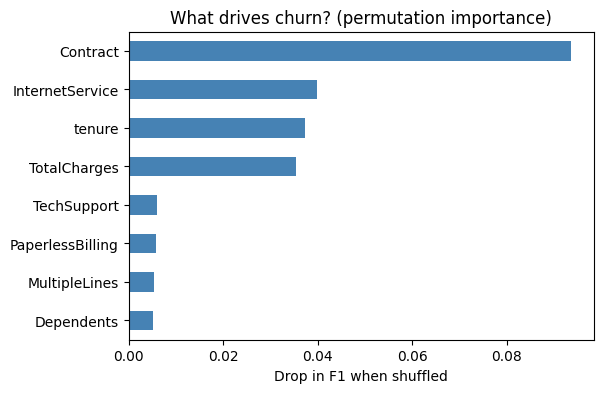


Tuned Random Forest CV F1: 0.637 (untuned: 0.631)
Best settings: {'model__n_estimators': 200, 'model__min_samples_leaf': 10, 'model__max_features': 'sqrt', 'model__max_depth': 8}

===== SUMMARY =====
Model: Random Forest | accuracy 0.771 | churn recall 0.74 | churn precision 0.55 | ROC-AUC 0.842


In [4]:
# ===============================================
# Telco Customer Churn: full modeling pipeline
# ===============================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, make_scorer,
                             precision_score, precision_recall_fscore_support,
                             ConfusionMatrixDisplay, RocCurveDisplay)

DATA_PATH = 'customer_churn.csv'
SEED = 42
RUN_TUNING = True          # set False to skip the (slower) tuning stepm
os.makedirs('images', exist_ok=True)

# ---------- 1. Load and clean ----------
df = pd.read_csv(DATA_PATH)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')   # 11 blanks -> NaN (tenure 0)
y = (df['Churn'] == 'Yes').astype(int)
X = df.drop(columns=['customerID', 'Churn'])                              # ID is not a feature
print(f'Customers: {len(df):,} | churn rate: {y.mean():.1%} | majority baseline accuracy: {1 - y.mean():.1%}')

num = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat = [c for c in X.columns if c not in num]

# Preprocessing lives inside the pipeline, so it is fitted on training data only (no leakage)
pre = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

# ---------- 2. Compare models with stratified 5-fold CV (training data only) ----------
models = {
    'Majority baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight='balanced', random_state=SEED, n_jobs=-1),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {'accuracy': 'accuracy',
           'precision': make_scorer(precision_score, zero_division=0),   # no warning for the baseline
           'recall': 'recall', 'f1': 'f1', 'roc_auc': 'roc_auc'}

rows = {}
for name, m in models.items():
    res = cross_validate(Pipeline([('pre', pre), ('model', m)]), X_train, y_train, cv=cv, scoring=scoring)
    rows[name] = {k: res[f'test_{k}'].mean() for k in scoring}
cv_table = pd.DataFrame(rows).T.round(3)
print('\n5-fold CV results (training data):')
print(cv_table)

# ---------- 3. Final model: chosen by CV F1, evaluated ONCE on the test set ----------
best = cv_table.drop('Majority baseline')['f1'].idxmax()
final = Pipeline([('pre', pre), ('model', models[best])]).fit(X_train, y_train)
proba = final.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f'\nBest model by CV F1: {best}')
print(classification_report(y_test, pred, target_names=['No churn', 'Churn']))
auc = roc_auc_score(y_test, proba)
print(f'ROC-AUC: {auc:.3f}')
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f'Confusion matrix -> caught churners: {tp} of {tp + fn} | false alarms: {fp} | missed: {fn}')

# ---------- 4. Charts ----------
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Stayed', 'Left']).plot(
    ax=ax, cmap='Blues', values_format='d')
ax.set_title(f'Confusion Matrix ({best}, test set)')
plt.savefig('images/confusion_matrix.png', dpi=150, bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(figsize=(5, 5))
RocCurveDisplay.from_predictions(y_test, proba, name=best, ax=ax)
ax.plot([0, 1], [0, 1], '--', color='gray', label='Random guessing')
ax.set_title('ROC Curve: Customer Churn Model'); ax.legend()
plt.savefig('images/roc_curve.png', dpi=150, bbox_inches='tight'); plt.show()

# ---------- 5. Threshold trade-off ----------
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (proba >= t).astype(int)
    pr, rc, f, _ = precision_recall_fscore_support(y_test, p, average='binary', zero_division=0)
    rows.append({'threshold': t, 'flagged': int(p.sum()), 'precision': round(pr, 2),
                 'recall': round(rc, 2), 'f1': round(f, 2)})
print('\nThreshold trade-off (test set):')
print(pd.DataFrame(rows).to_string(index=False))

# ---------- 6. Lift: how many churners are in the riskiest customers? ----------
ranked = pd.DataFrame({'y': y_test.values, 'p': proba}).sort_values('p', ascending=False)
rows = []
for frac in [0.1, 0.2, 0.3]:
    top = ranked.head(int(frac * len(ranked)))
    rows.append({'top_share_of_customers': f'{int(frac * 100)}%',
                 'share_of_all_churners_caught': f'{top.y.sum() / ranked.y.sum():.1%}',
                 'lift': round(top.y.mean() / ranked.y.mean(), 2)})
print('\nLift (riskiest customers first):')
print(pd.DataFrame(rows).to_string(index=False))

# ---------- 7. Which columns matter? Permutation importance on the test set ----------
pi = permutation_importance(final, X_test, y_test, scoring='f1', n_repeats=5,
                            random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False).head(8)
print('\nTop drivers (drop in F1 when the column is shuffled):')
print(imp.round(4))
fig, ax = plt.subplots(figsize=(6, 4))
imp.iloc[::-1].plot.barh(ax=ax, color='steelblue')
ax.set_title('What drives churn? (permutation importance)'); ax.set_xlabel('Drop in F1 when shuffled')
plt.savefig('images/feature_importance.png', dpi=150, bbox_inches='tight'); plt.show()

# ---------- 8. Hyperparameter tuning (training data only) ----------
if RUN_TUNING:
    grid = {'model__n_estimators': [200, 300, 500], 'model__max_depth': [None, 6, 8, 12],
            'model__min_samples_leaf': [3, 5, 10, 20], 'model__max_features': ['sqrt', 0.3, 0.5]}
    rs = RandomizedSearchCV(
        Pipeline([('pre', pre), ('model', RandomForestClassifier(class_weight='balanced',
                                                                 random_state=SEED, n_jobs=-1))]),
        grid, n_iter=20, scoring='f1', cv=cv, random_state=SEED, n_jobs=-1).fit(X_train, y_train)
    print(f"\nTuned Random Forest CV F1: {rs.best_score_:.3f} "
          f"(untuned: {cv_table.loc['Random Forest', 'f1']:.3f})")
    print('Best settings:', rs.best_params_)

# ---------- 9. Summary for the README / resume ----------
print('\n===== SUMMARY =====')
print(f'Model: {best} | accuracy {np.mean(pred == y_test):.3f} | churn recall {tp / (tp + fn):.2f} '
      f'| churn precision {tp / (tp + fp):.2f} | ROC-AUC {auc:.3f}')